# TotalSegmentator: banco, exame e rótulos cardíacos

Inspeção de um CT e suas máscaras de referência, sem inferência ou execução do pipeline. O inventário lê nomes de pastas e arquivos; somente o exame selecionado é carregado em memória.

### Imports

In [29]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.colors import to_rgb
from matplotlib.patches import Patch
from nibabel.funcs import as_closest_canonical
from nibabel.orientations import aff2axcodes

REPO_ROOT = next(
    path for path in (Path.cwd(), *Path.cwd().parents)
    if (path / "pyproject.toml").is_file()
)
if str(REPO_ROOT / "src") not in sys.path:
    sys.path.insert(0, str(REPO_ROOT / "src"))

from utils.project.runtime.notebook_env import (  # noqa: E402
    configure_notebook_environment,
    resolve_existing_path,
)
from utils.utils.nifti_io import load_raw_img_and_label  # noqa: E402
from utils.utils.roi import mask_bounding_box_slices  # noqa: E402
from utils.visualization.images.volume import visualize_label_map_3d  # noqa: E402

REPO_ROOT = configure_notebook_environment(chdir_to_src=False)

### Configuração

Altere `EXAM_ID` e `STRUCTURES` para inspecionar outro exame ou rótulo. O caminho pode ser definido por `TOTALSEGMENTATOR_BASE_PATH`; sem a variável, são procurados datasets nos discos montados. Índices `None` selecionam cortes com maior presença da estrutura de referência. `SHOW_3D` habilita a malha, sem salvar HTML.

In [30]:
# Procura o dataset nos discos montados sem fixar usuário ou nome do disco.
dataset_candidates = sorted(
    path
    for mount_root in (Path("/run/media"), Path("/media"))
    for path in mount_root.glob("*/*/DatasetsCCTA/Totalsegmentator_dataset_v*")
    if path.is_dir()
)
DATASET_ROOT = resolve_existing_path(
    "TOTALSEGMENTATOR_BASE_PATH", dataset_candidates, "TotalSegmentator"
)
EXAM_ID = "s0004"
STRUCTURES = ("aorta", "heart", "brachiocephalic_trunk")
REFERENCE_STRUCTURE = "heart"
WINDOW_HU = (-150, 500)
OVERLAY_ALPHA = 0.40
AXIAL_INDEX = None
CORONAL_INDEX = None
SAGITTAL_INDEX = None
SHOW_3D = True
MARGIN_3D_MM = 10.0
COLORS = ("#e74c3c", "#2ecc71", "#3498db", "#f1c40f", "#9b59b6")

## 1. Informações gerais do banco

As contagens representam CTs, classes distintas e arquivos de máscaras. **Um arquivo pode conter uma máscara vazia**: sua existência não confirma a estrutura anatômica no exame. Apenas os principais rótulos cardíacos e grandes vasos são listados.

In [31]:
CARDIAC_STRUCTURES = (
    "heart", "aorta", "atrial_appendage_left", "pulmonary_artery",
    "pulmonary_vein", "brachiocephalic_trunk", "superior_vena_cava",
    "inferior_vena_cava", "subclavian_artery_left", "subclavian_artery_right",
    "brachiocephalic_vein_left", "brachiocephalic_vein_right",
)
# Conta arquivos sem descomprimir todos os volumes do banco.
exam_dirs = sorted(
    path for path in DATASET_ROOT.glob("s*")
    if path.is_dir() and (path / "ct.nii.gz").is_file()
)
label_counts_by_exam = []
label_file_counts = {}
for directory in exam_dirs:
    label_paths = list((directory / "segmentations").glob("*.nii.gz"))
    label_counts_by_exam.append(len(label_paths))
    for label_path in label_paths:
        name = label_path.name.removesuffix(".nii.gz")
        label_file_counts[name] = label_file_counts.get(name, 0) + 1
if not exam_dirs:
    raise FileNotFoundError(f"Nenhum exame CT encontrado em {DATASET_ROOT}")
dataset_info_df = pd.DataFrame([
    ("Exames CT disponíveis", len(exam_dirs)),
    ("Exames com arquivos de rótulos", sum(count > 0 for count in label_counts_by_exam)),
    ("Classes de rótulos distintas (todo o banco)", len(label_file_counts)),
    ("Arquivos de máscaras (todo o banco)", sum(label_counts_by_exam)),
    ("Mínimo / máximo de arquivos de rótulos por exame",
     f"{min(label_counts_by_exam)} / {max(label_counts_by_exam)}"),
], columns=["informação", "quantidade"])
display(dataset_info_df)

,informação,quantidade
0,Exames CT disponíveis,1934
1,Exames com arquivos de rótulos,1934
2,Classes de rótulos distintas (todo o banco),117
3,Arquivos de máscaras (todo o banco),226256
4,Mínimo / máximo de arquivos de rótulos por exame,95 / 117


In [32]:
# Lista somente estruturas cardíacas e os grandes vasos próximos.
cardiac_labels_df = pd.DataFrame([
    {"rótulo": name, "exames_com_arquivo": label_file_counts[name]}
    for name in CARDIAC_STRUCTURES if name in label_file_counts
])
display(cardiac_labels_df)

,rótulo,exames_com_arquivo
0,heart,1934
1,aorta,1934
2,atrial_appendage_left,1934
3,pulmonary_vein,1934
4,brachiocephalic_trunk,1934
5,superior_vena_cava,1934
6,inferior_vena_cava,1934
7,subclavian_artery_left,1934
8,subclavian_artery_right,1934
9,brachiocephalic_vein_left,1934


## 2. Informações gerais de uma imagem

Carrega o CT e as máscaras escolhidas. A lista contém somente os principais rótulos cardíacos disponíveis neste exame.

In [33]:
exam_dir = DATASET_ROOT / EXAM_ID
image_path = exam_dir / "ct.nii.gz"
segmentation_dir = exam_dir / "segmentations"
if not image_path.is_file() or not segmentation_dir.is_dir():
    raise FileNotFoundError(f"Exame incompleto ou inexistente: {exam_dir}")
if not STRUCTURES or len(set(STRUCTURES)) != len(STRUCTURES):
    raise ValueError("Escolha ao menos uma estrutura, sem nomes repetidos.")
if WINDOW_HU[0] >= WINDOW_HU[1] or not 0 <= OVERLAY_ALPHA <= 1:
    raise ValueError("Janela HU ou opacidade inválida.")

available_structures = sorted(
    path.name.removesuffix(".nii.gz")
    for path in segmentation_dir.glob("*.nii.gz")
)
print(f"Exame: {EXAM_ID}")
print("Rótulos cardíacos disponíveis:", ", ".join(name for name in CARDIAC_STRUCTURES if name in available_structures))
missing = sorted(set(STRUCTURES) - set(available_structures))
if missing:
    raise FileNotFoundError(f"Rótulos ausentes neste exame: {missing}")

# Reorienta imagem e máscaras para RAS, preservando o alinhamento espacial.
raw_image, _ = load_raw_img_and_label(str(image_path))
image_nii = as_closest_canonical(raw_image)
image = np.asarray(image_nii.dataobj, dtype=np.float32)
spacing_xyz = tuple(float(value) for value in image_nii.header.get_zooms()[:3])
if image.ndim != 3:
    raise ValueError(f"Esperado volume 3D, recebido {image.shape}.")

masks = {}
for structure in STRUCTURES:
    _, raw_label = load_raw_img_and_label(
        str(image_path), str(segmentation_dir / f"{structure}.nii.gz")
    )
    if raw_label is None:
        raise RuntimeError(f"Rótulo não carregado: {structure}")
    label_nii = as_closest_canonical(raw_label)
    if label_nii.shape != image.shape or not np.allclose(
        label_nii.affine, image_nii.affine
    ):
        raise ValueError(f"Geometria do rótulo incompatível: {structure}")
    masks[structure] = np.asarray(label_nii.dataobj) > 0

Exame: s0004
Rótulos cardíacos disponíveis: heart, aorta, atrial_appendage_left, pulmonary_vein, brachiocephalic_trunk, superior_vena_cava, inferior_vena_cava, subclavian_artery_left, subclavian_artery_right, brachiocephalic_vein_left, brachiocephalic_vein_right


### Informações do CT

O número de fatias axiais é calculado **após a reorientação para RAS**, não pela quantidade de fatias ocupadas pelos rótulos. O campo de visão usa dimensões × espaçamento; não corresponde à extensão entre os centros dos voxels extremos.

O rótulo `aorta` reúne a aorta presente no campo de visão (ascendente, arco e descendente, incluindo o trecho abdominal quando coberto). Não há uma máscara separada da aorta ascendente entre os rótulos deste exame. Referência: [classes do TotalSegmentator](https://github.com/wasserth/TotalSegmentator) e [seções aórticas](https://github.com/wasserth/TotalSegmentator/blob/master/resources/aorta_report.md).

In [34]:
# Separa a geometria do CT das medidas das máscaras anatômicas.
fov_mm = np.asarray(image.shape) * np.asarray(spacing_xyz)
finite_intensities = image[np.isfinite(image)]
intensity_min = float(finite_intensities.min()) if finite_intensities.size else np.nan
intensity_max = float(finite_intensities.max()) if finite_intensities.size else np.nan
spatial_unit, time_unit = image_nii.header.get_xyzt_units()
ct_info_df = pd.DataFrame([
    ("Exame", EXAM_ID),
    ("Dimensões originais (eixos do arquivo)", str(raw_image.shape)),
    ("Orientação original", "".join(aff2axcodes(raw_image.affine))),
    ("Dimensões após reorientação (x, y, z)", str(image.shape)),
    ("Orientação de visualização", "".join(aff2axcodes(image_nii.affine))),
    ("Fatias axiais do CT", image.shape[2]),
    ("Posições coronais / sagitais", f"{image.shape[1]} / {image.shape[0]}"),
    ("Espaçamento (x, y, z) em mm", str(tuple(round(v, 4) for v in spacing_xyz))),
    ("Campo de visão (x, y, z) em mm", str(tuple(round(float(v), 2) for v in fov_mm))),
    ("Unidade espacial declarada no NIfTI", spatial_unit),
    ("Total de voxels do CT", int(np.prod(image.shape))),
    ("Volume do campo de visão em ml", round(float(np.prod(fov_mm)) / 1000, 2)),
    ("Tipo armazenado no NIfTI", str(raw_image.get_data_dtype())),
    ("Intensidade mínima / máxima (HU)", f"{intensity_min:.1f} / {intensity_max:.1f}"),
], columns=["informação", "valor"])
display(ct_info_df)

,informação,valor
0,Exame,s0004
1,Dimensões originais (eixos do arquivo),"(255, 177, 440)"
2,Orientação original,RAS
3,"Dimensões após reorientação (x, y, z)","(255, 177, 440)"
4,Orientação de visualização,RAS
5,Fatias axiais do CT,440
6,Posições coronais / sagitais,177 / 255
7,"Espaçamento (x, y, z) em mm","(1.5, 1.5, 1.5)"
8,"Campo de visão (x, y, z) em mm","(382.5, 265.5, 660.0)"
9,Unidade espacial declarada no NIfTI,unknown


### Informações dos rótulos selecionados

Volume, número de fatias ocupadas e cobertura axial das máscaras no exame selecionado.

In [35]:
structure_colors = {
    name: COLORS[index % len(COLORS)]
    for index, name in enumerate(STRUCTURES)
}
voxel_volume_mm3 = float(np.prod(spacing_xyz))
summary_df = pd.DataFrame([
    {
        "estrutura": name,
        "voxels": int(mask.sum()),
        "volume_ml": float(mask.sum()) * voxel_volume_mm3 / 1000,
        "fatias_axiais": int(np.count_nonzero(mask.any(axis=(0, 1)))),
        "cobertura_axial_pct": 100 * np.count_nonzero(mask.any(axis=(0, 1))) / image.shape[2],
    }
    for name, mask in masks.items()
])
display(summary_df)

,estrutura,voxels,volume_ml,fatias_axiais,cobertura_axial_pct
0,aorta,56876,191.956485,218,49.545455
1,heart,151313,510.681334,74,16.818182
2,brachiocephalic_trunk,690,2.328750,15,3.409091


## 3. Exemplo da imagem e dos rótulos

Cada vista fica em sua própria célula, com campo de visão completo e proporções físicas.

In [36]:
# Seleciona os cortes sem armazenar coordenadas de todos os voxels.
union_mask = np.logical_or.reduce(list(masks.values()))
reference_mask = masks.get(REFERENCE_STRUCTURE, union_mask)
if not reference_mask.any():
    reference_mask = union_mask

slice_indices = {}
for axis, requested in enumerate((SAGITTAL_INDEX, CORONAL_INDEX, AXIAL_INDEX)):
    if requested is None:
        counts = reference_mask.sum(axis=tuple(dim for dim in range(3) if dim != axis))
        index = int(counts.argmax()) if counts.any() else image.shape[axis] // 2
    else:
        index = int(requested)
    if not 0 <= index < image.shape[axis]:
        raise IndexError(f"Índice {index} fora do eixo {axis}.")
    slice_indices[axis] = index

def display_labeled_slice(axis, *, overlay=True):
    """Exibe o campo de visão completo com máscaras coloridas opcionais."""
    index = slice_indices[axis]
    remaining_axes = [dim for dim in range(3) if dim != axis]
    view_names = {0: "Sagital", 1: "Coronal", 2: "Axial"}
    slice_image = np.take(image, index, axis=axis).T
    width_mm = slice_image.shape[1] * spacing_xyz[remaining_axes[0]]
    height_mm = slice_image.shape[0] * spacing_xyz[remaining_axes[1]]
    extent = (0, width_mm, 0, height_mm)
    fig, ax = plt.subplots(figsize=(7, 7), dpi=100)
    ax.imshow(
        slice_image, cmap="gray", origin="lower", extent=extent,
        vmin=WINDOW_HU[0], vmax=WINDOW_HU[1], interpolation="nearest",
    )
    if overlay:
        handles = []
        for name, mask in masks.items():
            mask_slice = np.take(mask, index, axis=axis).T
            rgba = np.zeros((*mask_slice.shape, 4), dtype=np.float32)
            rgba[..., :3] = to_rgb(structure_colors[name])
            rgba[..., 3] = mask_slice * OVERLAY_ALPHA
            ax.imshow(rgba, origin="lower", extent=extent, interpolation="nearest")
            handles.append(Patch(color=structure_colors[name], label=name))
        ax.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, -0.02))
    ax.set_xlim(0, width_mm)
    ax.set_ylim(0, height_mm)
    ax.set_aspect("equal")
    ax.set_title(f"{EXAM_ID} — {view_names[axis]} — índice {index}")
    ax.axis("off")
    plt.tight_layout()
    plt.show()
    plt.close(fig)

### Imagem axial sem rótulos

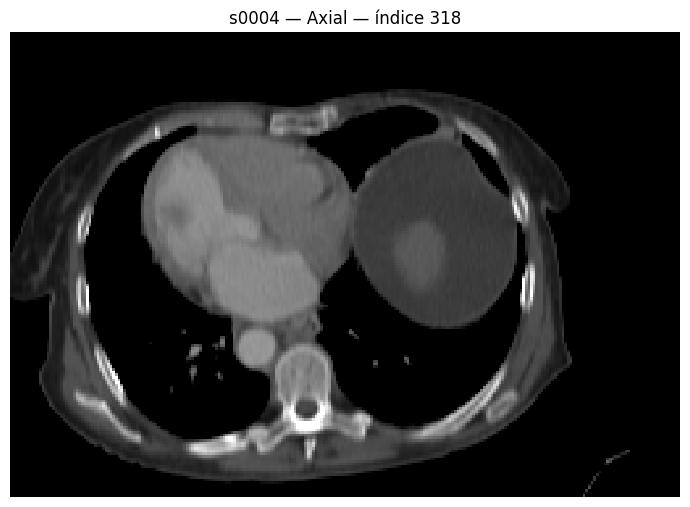

In [37]:
display_labeled_slice(2, overlay=False)

### Imagem axial com rótulos

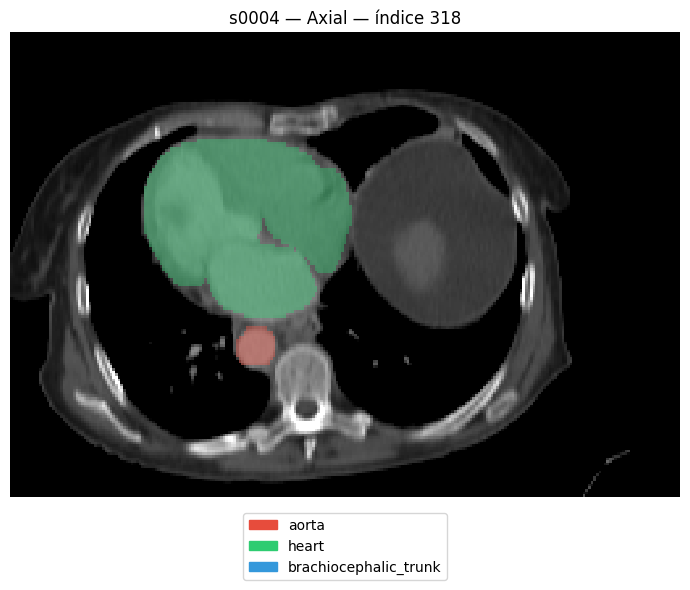

In [38]:
display_labeled_slice(2)

### Imagem coronal com rótulos

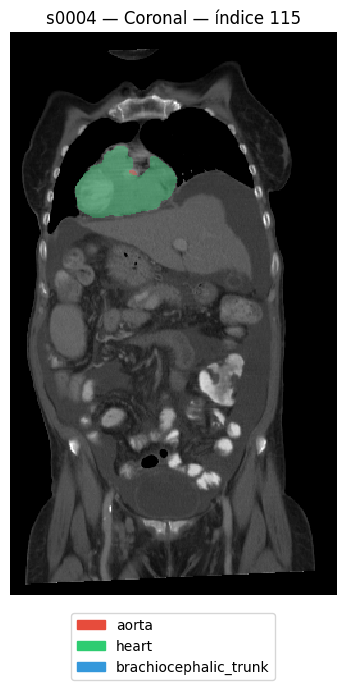

In [39]:
display_labeled_slice(1)

### Imagem sagital com rótulos

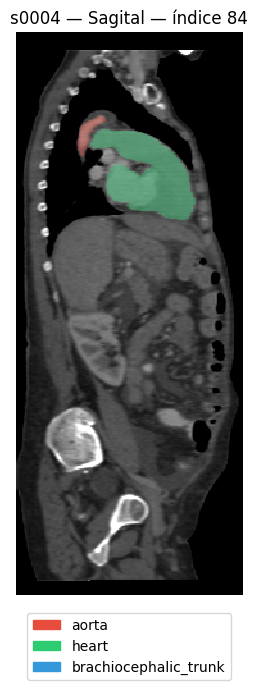

In [40]:
display_labeled_slice(0)

### Estruturas em 3D (opcional)

Apenas a cena 3D usa uma ROI em torno dos rótulos para reduzir o custo de geração da malha. As vistas 2D acima continuam completas. Em eventuais sobreposições entre máscaras, a última estrutura selecionada tem prioridade na cena.

In [41]:
if SHOW_3D:
    if not union_mask.any():
        raise ValueError("As máscaras selecionadas estão vazias.")
    crop_slices = mask_bounding_box_slices(union_mask, spacing_xyz, MARGIN_3D_MM)
    label_map = np.zeros(union_mask[crop_slices].shape, dtype=np.uint16)
    label_specs = {}
    for label_value, (name, mask) in enumerate(masks.items(), start=1):
        label_map[mask[crop_slices]] = label_value
        label_specs[label_value] = (
            name, int(structure_colors[name].removeprefix("#"), 16)
        )
    plot = visualize_label_map_3d(
        label_map, label_specs, spacing=spacing_xyz, display_plot=False,
        plot_name=f"TotalSegmentator: {EXAM_ID}",
    )
    display(plot)
else:
    print("Visualização 3D desativada. Use SHOW_3D = True para habilitar.")

Plot(antialias=3, axes=['X (mm)', 'Y (mm)', 'Z (mm)'], axes_helper=1.0, axes_helper_colors=[16711680, 65280, 2…